In [1]:
# -------------------------------------------------------------------------
# 0. Dependencies Installation (FAISS + TorchXRayVision + Transformers)
# -------------------------------------------------------------------------
!pip install torchxrayvision --no-deps -q
!pip install transformers faiss-cpu scikit-image nltk matplotlib rouge-score seaborn scikit-learn -q


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 29.0/29.0 MB 49.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.8/18.8 MB 89.1 MB/s eta 0:00:00


In [2]:
# -------------------------------------------------------------------------
# 1. Comprehensive Data Manifest & RAG Text Corpus Generation
# -------------------------------------------------------------------------
import os, sys, json, subprocess, zipfile, pandas as pd, numpy as np
from pathlib import Path
from sklearn.model_selection import GroupShuffleSplit

work_dir = "/kaggle/working"
os.makedirs(work_dir, exist_ok=True)
os.chdir(work_dir)

try:
    from kaggle_secrets import UserSecretsClient
    user_secrets = UserSecretsClient()
    PHYSIONET_USER = user_secrets.get_secret("PHYSIONET_USER")
    PHYSIONET_PASS = user_secrets.get_secret("PHYSIONET_PASS")
except Exception:
    PHYSIONET_USER = os.environ.get("PHYSIONET_USER", "")
    PHYSIONET_PASS = os.environ.get("PHYSIONET_PASS", "")

netrc_content = "machine physionet.org\nlogin " + str(PHYSIONET_USER) + "\npassword " + str(PHYSIONET_PASS) + "\n"
netrc_path = os.path.expanduser("~/.netrc")
with open(netrc_path, "w", encoding="utf-8") as f:
    f.write(netrc_content)
os.chmod(netrc_path, 0o600)

metadata_files = [
    ("meta.csv", "https://physionet.org/files/mimic-cxr-jpg/2.1.0/mimic-cxr-2.0.0-metadata.csv.gz"),
    ("chexpert.csv", "https://physionet.org/files/mimic-cxr-jpg/2.1.0/mimic-cxr-2.0.0-chexpert.csv.gz"),
]

for target_name, url in metadata_files:
    if not os.path.exists(target_name):
        gz_name = target_name + ".gz"
        subprocess.run("wget -q --netrc -O " + gz_name + " " + url, shell=True, check=True)
        subprocess.run("gunzip -f " + gz_name, shell=True, check=True)

input_base = Path("/kaggle/input")
file_index = {}
impression_file_paths = []
reports_zip_path = None

for root, _, files in os.walk(input_base):
    for f in files:
        full_path = os.path.join(root, f)
        if f in ["mimic_train_impressions.csv", "train_imp.csv", "mimic_test_impressions.csv", "test_imp.csv"]:
            if full_path not in impression_file_paths:
                impression_file_paths.append(full_path)
        elif f == "mimic-cxr-reports.zip":
            reports_zip_path = full_path
        elif f.endswith(".jpg"):
            parts = full_path.split("/")
            rel_path = None
            for prefix in ("p10", "p11"):
                if prefix in parts:
                    idx = parts.index(prefix)
                    rel_path = "/".join(parts[idx:])
                    break
            if rel_path is not None and rel_path not in file_index:
                file_index[rel_path] = full_path

if not impression_file_paths:
    sys.exit("Error: No report impression CSV files found in /kaggle/input/.")

# Pool Verification & Gate Threshold (75,216 total images reference pool)
TOTAL_REFERENCE_POOL = 75216
indexed_count = len(file_index)
coverage_pct = (indexed_count / TOTAL_REFERENCE_POOL) * 100.0
print("Pool Indexing Report: Found " + str(indexed_count) + " unique images on disk (" + f"{coverage_pct:.1f}%" + " of 75,216 reference pool).")

if coverage_pct < 90.0:
    print("WARNING: Dataset Pool Coverage is below 90%. Ensure all p10 and p11 image archives are attached!")

report_dfs = [pd.read_csv(p) for p in impression_file_paths]
report_df = pd.concat(report_dfs, ignore_index=True).drop_duplicates(subset=["dicom_id"])

meta_df = pd.read_csv("meta.csv")
chex_df = pd.read_csv("chexpert.csv")

# U-Zeros Labeling Policy (Mapping NaN and -1.0 Uncertainty to 0.0 following Irvin et al., 2019)
chex_label_cols = [c for c in chex_df.columns if c not in ["subject_id", "study_id"]]
for c in chex_label_cols:
    chex_df[c] = chex_df[c].fillna(0.0)
    chex_df[c] = chex_df[c].replace(-1.0, 0.0)

mask_cohort = (meta_df["subject_id"] >= 10000000) & (meta_df["subject_id"] < 12000000)
meta_cohort = meta_df[mask_cohort].copy()

merged_df = pd.merge(meta_cohort, chex_df[["study_id"] + chex_label_cols], on="study_id", how="inner")
merged_df = pd.merge(merged_df, report_df[["dicom_id", "report"]], on="dicom_id", how="left")
merged_df = merged_df.dropna(subset=["report"]).reset_index(drop=True)

def get_path(row):
    subject_id = int(row["subject_id"])
    study_id = int(row["study_id"])
    prefix = "p10" if subject_id < 11000000 else "p11"
    rel = prefix + "/p" + str(subject_id) + "/s" + str(study_id) + "/" + str(row["dicom_id"]) + ".jpg"
    return file_index.get(rel, None)

merged_df["image_path"] = merged_df.apply(get_path, axis=1)
merged_df = merged_df.dropna(subset=["image_path"]).reset_index(drop=True)

# -------------------------------------------------------------------------
# Optional: Enrich reports from mimic-cxr-reports.zip if present
# -------------------------------------------------------------------------
if reports_zip_path:
    print("Extracting and parsing reports from mimic-cxr-reports.zip...")
    study_map = {}
    for idx, row in merged_df.iterrows():
        study_map[(int(row["subject_id"]), int(row["study_id"]))] = idx
        
    reports_dict = {}
    with zipfile.ZipFile(reports_zip_path) as z:
        for name in z.namelist():
            if name.endswith(".txt"):
                parts = name.split("/")
                if len(parts) >= 4:
                    try:
                        sub_id = int(parts[2][1:])
                        std_id = int(parts[3][1:-4])
                        if (sub_id, std_id) in study_map:
                            with zipfile.ZipFile(reports_zip_path).open(name) as f:
                                text = f.read().decode('utf-8', errors='ignore')
                                lower_text = text.lower()
                                imp_idx = lower_text.find("impression:")
                                if imp_idx != -1:
                                    imp = text[imp_idx + len("impression:"):].strip()
                                else:
                                    imp = text.strip()
                                reports_dict[study_map[(sub_id, std_id)]] = " ".join(imp.split())
                    except Exception:
                        pass
                        
    replaced_count = 0
    for idx, text in reports_dict.items():
        if text:
            merged_df.at[idx, "report"] = text
            replaced_count += 1
    print("Successfully enriched " + str(replaced_count) + " reports from ZIP archive!")
else:
    print("mimic-cxr-reports.zip not detected. RAG Text Corpus will use Train Set report impressions.")

print("Total valid matched instances on disk: " + str(len(merged_df)))

np.random.seed(42)
gss_train = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
train_idx, temp_idx = next(gss_train.split(merged_df, groups=merged_df["subject_id"]))

train_df = merged_df.iloc[train_idx].copy()
temp_df = merged_df.iloc[temp_idx].copy()

gss_val = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=42)
val_idx, test_idx = next(gss_val.split(temp_df, groups=temp_df["subject_id"]))

val_df = temp_df.iloc[val_idx].copy()
test_df = temp_df.iloc[test_idx].copy()

# Audit & Proposal Policy Implementation for Rare Classes
rare_classes = ['Enlarged Cardiomediastinum', 'Fracture', 'Lung Lesion', 'Pleural Other']
print("Rare Pathology Test Set Coverage Check (Official CheXpert Labels, Threshold N >= 150):")

for rc in rare_classes:
    rc_count = int(test_df[rc].sum())
    status = "OK (N >= 150)" if rc_count >= 150 else "FLAGGED: LOW SAMPLE (N < 150)"
    print("  - " + f"{rc:<28}" + ": " + str(rc_count) + " cases [" + status + "]")

train_df["split"] = "train"
val_df["split"] = "val"
test_df["split"] = "test"

master_df = pd.concat([train_df, val_df, test_df], ignore_index=True)
master_df.to_csv("/kaggle/working/mimic_master_split.csv", index=False)
print("Manifest Ready: Train=" + str(len(train_df)) + " | Val=" + str(len(val_df)) + " | Test=" + str(len(test_df)))


Pool Indexing Report: Found 73995 unique images on disk (98.4% of 75,216 reference pool).
mimic-cxr-reports.zip not detected. RAG Text Corpus will use Train Set report impressions.
Total valid matched instances on disk: 62754
Rare Pathology Test Set Coverage Check (Official CheXpert Labels, Threshold N >= 150):
  - Enlarged Cardiomediastinum  : 129 cases [FLAGGED: LOW SAMPLE (N < 150)]
  - Fracture                    : 136 cases [FLAGGED: LOW SAMPLE (N < 150)]
  - Lung Lesion                 : 183 cases [OK (N >= 150)]
  - Pleural Other               : 62 cases [FLAGGED: LOW SAMPLE (N < 150)]
Manifest Ready: Train=50176 | Val=6190 | Test=6388


Compute Device: cuda


config.json:   0%|          | 0.00/762 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

... (29 outputs left out)

Epoch 9/10 [Val]: 100%|██████████| 387/387 [00:21<00:00, 17.83it/s]



--- Epoch 9 Summary ---
Train Loss : Joint = 1.1803 | Text = 0.9273 | Cls = 0.2530
Val Loss   : Joint = 1.3837 | Text = 1.1256 | Cls = 0.2582
Classifier : Val Macro-AUROC = 0.7321 | Val Macro-F1 = 0.1067
GATE 1     : BLEU-1 = 0.2644 (Target >= 0.25) | Distinct-2 = 0.9772 (Target >= 0.15)
--------------------------------------------------
>>> Best Checkpoint Saved <<<


Epoch 10/10 [Val]: 100%|██████████| 387/387 [00:21<00:00, 17.95it/s]



--- Epoch 10 Summary ---
Train Loss : Joint = 1.1389 | Text = 0.8862 | Cls = 0.2527
Val Loss   : Joint = 1.3784 | Text = 1.1206 | Cls = 0.2578
Classifier : Val Macro-AUROC = 0.7340 | Val Macro-F1 = 0.1167
GATE 1     : BLEU-1 = 0.2724 (Target >= 0.25) | Distinct-2 = 0.9651 (Target >= 0.15)
--------------------------------------------------
>>> Best Checkpoint Saved <<<


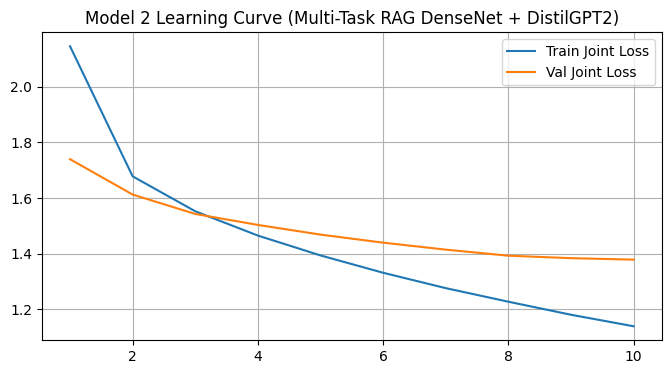

In [3]:
# -------------------------------------------------------------------------
# 2. FAISS Vector Retrieval Indexing & Model 2 (RAG) Multi-Task Training Loop
# -------------------------------------------------------------------------
import os, random, faiss, torch, torch.nn as nn, torch.optim as optim, torch.nn.functional as F
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, GPT2LMHeadModel
from tqdm import tqdm
import torchxrayvision as xrv
import nltk
from nltk.translate.bleu_score import sentence_bleu, SmoothingFunction
from nltk.util import ngrams
from sklearn.metrics import roc_auc_score, f1_score

nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)

def seed_everything(seed=42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Compute Device: " + str(device))

master_df = pd.read_csv("/kaggle/working/mimic_master_split.csv")
tokenizer = AutoTokenizer.from_pretrained("distilgpt2")
special_tokens = {"bos_token": "<bos>", "eos_token": "<eos>", "pad_token": "<pad>", "additional_special_tokens": ["<rag>", "</rag>", "<report>", "</report>"]}
tokenizer.add_special_tokens(special_tokens)
vocab_size = len(tokenizer)
pad_id, bos_id, eos_id = tokenizer.pad_token_id, tokenizer.bos_token_id, tokenizer.eos_token_id
rag_start_id = tokenizer.convert_tokens_to_ids("<rag>")
rag_end_id   = tokenizer.convert_tokens_to_ids("</rag>")

chex_label_cols = [
    'Atelectasis', 'Cardiomegaly', 'Consolidation', 'Edema', 'Enlarged Cardiomediastinum',
    'Fracture', 'Lung Lesion', 'Lung Opacity', 'No Finding', 'Pleural Effusion',
    'Pleural Other', 'Pneumonia', 'Pneumothorax', 'Support Devices'
]

train_df = master_df[master_df['split'] == 'train'].reset_index(drop=True)
val_df   = master_df[master_df['split'] == 'val'].reset_index(drop=True)
test_df  = master_df[master_df['split'] == 'test'].reset_index(drop=True)

# -------------------------------------------------------------------------
# Batched High-Speed Visual Feature Extraction System
# -------------------------------------------------------------------------
class DenseNetFeatureExtractor(nn.Module):
    def __init__(self):
        super().__init__()
        densenet = xrv.models.DenseNet(weights="densenet121-res224-mimic_ch")
        self.encoder = densenet.features
        for param in self.encoder.parameters():
            param.requires_grad = False
            
    def forward(self, x):
        features = self.encoder(x)
        spatial_tokens = features.flatten(2).permute(0, 2, 1) # [B, 49, 1024]
        mean_features = spatial_tokens.mean(dim=1)              # [B, 1024]
        return spatial_tokens, mean_features

print("Initializing Feature Extractor...")
feature_extractor = DenseNetFeatureExtractor().to(device)
feature_extractor.eval()

class FeatureExtractionDataset(Dataset):
    def __init__(self, df):
        self.df = df.reset_index(drop=True)
    def __len__(self):
        return len(self.df)
    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        try:
            img = Image.open(row['image_path']).convert('L').resize((224, 224))
            img_np = np.array(img, dtype=np.float32)
            img_norm = xrv.datasets.normalize(img_np, maxval=255)
            image_tensor = torch.tensor(img_norm, dtype=torch.float32).unsqueeze(0)
        except Exception:
            image_tensor = torch.zeros((1, 224, 224), dtype=torch.float32)
        return image_tensor, idx

def extract_all_visual_features_batched(df, batch_size=128):
    dataset = FeatureExtractionDataset(df)
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=True)
    
    mean_feats_raw = np.zeros((len(df), 1024), dtype=np.float32)
    mean_feats_norm = np.zeros((len(df), 1024), dtype=np.float32)
    spatial_feats_all = np.zeros((len(df), 49, 1024), dtype=np.float16)
    
    print("Extracting visual features in batches of " + str(batch_size) + "...")
    with torch.no_grad():
        for batch_imgs, batch_idxs in tqdm(loader, desc="Visual Feature Extraction"):
            batch_imgs = batch_imgs.to(device, non_blocking=True)
            spatial_tokens, mean_features = feature_extractor(batch_imgs)
            
            raw_cpu = mean_features.cpu().numpy()
            norm_cpu = F.normalize(mean_features, p=2, dim=1).cpu().numpy()
            spatial_cpu = spatial_tokens.cpu().numpy().astype(np.float16)
            
            for i, idx in enumerate(batch_idxs.numpy()):
                mean_feats_raw[idx] = raw_cpu[i]
                mean_feats_norm[idx] = norm_cpu[i]
                spatial_feats_all[idx] = spatial_cpu[i]
                
    return mean_feats_raw, mean_feats_norm, spatial_feats_all

print("Extracting features for Training Set...")
train_raw, train_norm, train_spatial = extract_all_visual_features_batched(train_df)
print("Extracting features for Validation Set...")
val_raw, val_norm, val_spatial = extract_all_visual_features_batched(val_df)
print("Extracting features for Test Set...")
test_raw, test_norm, test_spatial = extract_all_visual_features_batched(test_df)

# Release feature extractor from GPU VRAM
del feature_extractor
torch.cuda.empty_cache()

# -------------------------------------------------------------------------
# FAISS Index Construction (Uses L2-Normalized Features)
# -------------------------------------------------------------------------
embedding_dim = 1024
faiss_index = faiss.IndexFlatIP(embedding_dim)
faiss_index.add(train_norm)
print("FAISS Index Ready: Added " + str(faiss_index.ntotal) + " training dense vectors.")

# -------------------------------------------------------------------------
# High-Speed RAG Pre-calculation using pre-extracted normalized features
# -------------------------------------------------------------------------
def precalculate_rag_reports(df, train_df, mean_feats_norm, is_train=True):
    print("Pre-calculating FAISS retrievals...")
    k_search = 2 if is_train else 1
    D, I = faiss_index.search(mean_feats_norm, k_search)
    
    retrieved_reports = []
    for idx in range(len(df)):
        retrieved_idx = I[idx][0]
        if is_train and retrieved_idx == idx and k_search > 1:
            retrieved_idx = I[idx][1]
        
        rep = str(train_df.iloc[retrieved_idx]['report']) if pd.notna(train_df.iloc[retrieved_idx]['report']) else ""
        retrieved_reports.append(rep)
    return retrieved_reports

print("Running Pre-calculation for splits...")
train_df["retrieved_report"] = precalculate_rag_reports(train_df, train_df, train_norm, is_train=True)
val_df["retrieved_report"] = precalculate_rag_reports(val_df, train_df, val_norm, is_train=False)
test_df["retrieved_report"] = precalculate_rag_reports(test_df, train_df, test_norm, is_train=False)

# -------------------------------------------------------------------------
# RAM-based RAG Multi-Task Dataset & DataLoader (Uses Raw mean_feats for Classifier Alignment)
# -------------------------------------------------------------------------
class MultiTaskRAGDataset(Dataset):
    def __init__(self, df, spatial_feats, mean_feats, tokenizer, max_seq_len=120):
        self.df = df.reset_index(drop=True)
        self.spatial_feats = spatial_feats
        self.mean_feats = mean_feats
        self.tokenizer = tokenizer
        self.max_seq_len = max_seq_len

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        
        spatial_token = torch.tensor(self.spatial_feats[idx], dtype=torch.float32)
        mean_feature = torch.tensor(self.mean_feats[idx], dtype=torch.float32)
        
        retrieved_report = str(row['retrieved_report'])
        target_report = str(row['report']) if pd.notna(row['report']) else ""

        full_prompt = "<bos> <rag> " + retrieved_report + " </rag> <report> " + target_report + " <eos>"
        tokenized = self.tokenizer(
            full_prompt,
            max_length=self.max_seq_len,
            padding="max_length",
            truncation=True,
            return_tensors="pt"
        )
        
        labels_vector = torch.tensor([float(row[c]) for c in chex_label_cols], dtype=torch.float32)
        
        return {
            "spatial_tokens": spatial_token,
            "mean_features": mean_feature,
            "input_ids": tokenized["input_ids"].squeeze(0),
            "labels": labels_vector,
            "retrieved_report": retrieved_report
        }

train_dataset = MultiTaskRAGDataset(train_df, train_spatial, train_raw, tokenizer)
val_dataset   = MultiTaskRAGDataset(val_df, val_spatial, val_raw, tokenizer)
test_dataset  = MultiTaskRAGDataset(test_df, test_spatial, test_raw, tokenizer)

# Safe to use num_workers=2 since dataset __getitem__ only reads from RAM (0% disk I/O)
BATCH_SIZE, ACCUMULATION_STEPS = 16, 2
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

print("DataLoaders Ready: Train=" + str(len(train_loader)) + " batches | Val=" + str(len(val_loader)) + " batches")

class MultiTaskRAGDenseNetDistilGPT2(nn.Module):
    def __init__(self, vocab_size, num_classes=14, pad_token_id=0):
        super().__init__()
        self.pad_token_id = pad_token_id
        
        # 14-Class CheXpert Classification Head
        self.classifier_head = nn.Sequential(
            nn.Linear(1024, 256),
            nn.GELU(),
            nn.Dropout(0.2),
            nn.Linear(256, num_classes)
        )
            
        # Visual Projection Layer for Transformer
        self.visual_projection = nn.Sequential(
            nn.Linear(1024, 768),
            nn.GELU(),
            nn.Linear(768, 768),
            nn.LayerNorm(768)
        )
        
        self.decoder = GPT2LMHeadModel.from_pretrained("distilgpt2")
        self.decoder.resize_token_embeddings(vocab_size)

    def forward(self, spatial_tokens, mean_features, input_ids):
        batch_size, seq_len = input_ids.shape
        
        # 1. CheXpert Classification Logits
        cls_logits = self.classifier_head(mean_features) # [B, 14]
        
        # 2. Text Generation Logits with RAG Context Prompting
        visual_embeds = self.visual_projection(spatial_tokens) # [B, 49, 768]
        text_embeds = self.decoder.transformer.wte(input_ids)  # [B, seq_len, 768]
        inputs_embeds = torch.cat([visual_embeds, text_embeds], dim=1) # [B, 49 + seq_len, 768]
        
        vis_pos_ids = torch.arange(0, 49, dtype=torch.long, device=input_ids.device).unsqueeze(0).repeat(batch_size, 1)
        text_pos_ids = torch.arange(0, seq_len, dtype=torch.long, device=input_ids.device).unsqueeze(0).repeat(batch_size, 1)
        position_ids = torch.cat([vis_pos_ids, text_pos_ids], dim=1)
        
        vis_attn = torch.ones((batch_size, 49), device=input_ids.device)
        text_attn = (input_ids != self.pad_token_id).float()
        attention_mask = torch.cat([vis_attn, text_attn], dim=1)
        
        outputs = self.decoder(inputs_embeds=inputs_embeds, position_ids=position_ids, attention_mask=attention_mask)
        logits = outputs.logits
        text_logits = logits[:, 49:-1, :].contiguous()
        
        return text_logits, cls_logits

    @torch.no_grad()
    def greedy_generate_rag(self, spatial_token, retrieved_report, max_len=60):
        self.eval()
        if spatial_token.dim() == 2:
            spatial_token = spatial_token.unsqueeze(0)
            
        visual_embeds = self.visual_projection(spatial_token) # [1, 49, 768]
        
        prompt_str = "<bos> <rag> " + str(retrieved_report) + " </rag> <report>"
        prompt_toks = tokenizer(prompt_str, return_tensors="pt")["input_ids"].to(spatial_token.device)
        prompt_len = prompt_toks.shape[1]
        
        text_embeds = self.decoder.transformer.wte(prompt_toks)
        inputs_embeds = torch.cat([visual_embeds, text_embeds], dim=1)
        
        vis_pos_ids = torch.arange(0, 49, dtype=torch.long, device=spatial_token.device).unsqueeze(0)
        prompt_pos_ids = torch.arange(0, prompt_len, dtype=torch.long, device=spatial_token.device).unsqueeze(0)
        pos_ids = torch.cat([vis_pos_ids, prompt_pos_ids], dim=1)
        
        outputs = self.decoder(inputs_embeds=inputs_embeds, position_ids=pos_ids, use_cache=True)
        next_token_logits = outputs.logits[:, -1, :]
        next_id = next_token_logits.argmax(-1).item()
        past_key_values = outputs.past_key_values
        
        generated_ids = []
        if next_id != eos_id:
            generated_ids.append(next_id)
            current_ids = torch.tensor([[next_id]], device=spatial_token.device)
        else:
            current_ids = torch.tensor([[eos_id]], device=spatial_token.device)
            
        for step in range(max_len):
            if next_id == eos_id:
                break
                
            curr_pos_id = torch.tensor([[prompt_len + step]], dtype=torch.long, device=spatial_token.device)
            outputs = self.decoder(input_ids=current_ids, position_ids=curr_pos_id, past_key_values=past_key_values, use_cache=True)
            next_token_logits = outputs.logits[:, -1, :]
            next_id = next_token_logits.argmax(-1).item()
            past_key_values = outputs.past_key_values
            
            if next_id == eos_id:
                break
            generated_ids.append(next_id)
            current_ids = torch.tensor([[next_id]], device=spatial_token.device)
            
        return generated_ids

model = MultiTaskRAGDenseNetDistilGPT2(vocab_size=vocab_size, pad_token_id=pad_id).to(device)
optimizer = optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=5e-5, weight_decay=1e-2)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=2)

criterion_text = nn.CrossEntropyLoss(ignore_index=pad_id)
criterion_cls  = nn.BCEWithLogitsLoss()
scaler = torch.amp.GradScaler("cuda")

checkpoint_path = "/kaggle/working/model_2_resumable.pt"
start_epoch, best_val_loss = 1, float('inf')
train_losses, val_losses = [], []

if os.path.exists(checkpoint_path):
    checkpoint = torch.load(checkpoint_path, map_location=device)
    model.load_state_dict(checkpoint['model_state'])
    optimizer.load_state_dict(checkpoint['optimizer_state'])
    scheduler.load_state_dict(checkpoint['scheduler_state'])
    scaler.load_state_dict(checkpoint['scaler_state'])
    start_epoch = checkpoint['epoch'] + 1
    best_val_loss = checkpoint['best_val_loss']
    train_losses = checkpoint.get('train_losses', [])
    val_losses = checkpoint.get('val_losses', [])
    print("Resumed at Epoch " + str(start_epoch))

trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print("Model 2 (Multi-Task RAG DenseNet + DistilGPT2) Initialized. Trainable Params: " + str(trainable_params))

EPOCHS = 10
LAMBDA_CLS = 1.0 
smooth = SmoothingFunction().method1

torch.cuda.empty_cache()

for epoch in range(start_epoch, EPOCHS + 1):
    model.train()
    total_train_loss, total_train_text_loss, total_train_cls_loss = 0.0, 0.0, 0.0
    optimizer.zero_grad()
    loop = tqdm(train_loader, desc="Epoch " + str(epoch) + "/" + str(EPOCHS) + " [Train]")
    
    for i, batch in enumerate(loop):
        spatial_tokens = batch["spatial_tokens"].to(device, non_blocking=True)
        mean_features = batch["mean_features"].to(device, non_blocking=True)
        input_ids = batch["input_ids"].to(device, non_blocking=True)
        labels = batch["labels"].to(device, non_blocking=True)
        targets = input_ids[:, 1:].contiguous()
        
        try:
            with torch.amp.autocast("cuda"):
                text_logits, cls_logits = model(spatial_tokens, mean_features, input_ids)
                loss_text = criterion_text(text_logits.reshape(-1, vocab_size), targets.reshape(-1))
                loss_cls  = criterion_cls(cls_logits, labels)
                joint_loss = (loss_text + LAMBDA_CLS * loss_cls) / ACCUMULATION_STEPS
                
            scaler.scale(joint_loss).backward()
            if (i + 1) % ACCUMULATION_STEPS == 0 or (i + 1) == len(train_loader):
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                scaler.step(optimizer)
                scaler.update()
                optimizer.zero_grad()
                
            total_train_loss += joint_loss.item() * ACCUMULATION_STEPS
            total_train_text_loss += loss_text.item()
            total_train_cls_loss += loss_cls.item()
            
            loop.set_postfix(
                joint=f"{joint_loss.item() * ACCUMULATION_STEPS:.4f}",
                text=f"{loss_text.item():.4f}",
                cls=f"{loss_cls.item():.4f}"
            )
        except RuntimeError as e:
            if "out of memory" in str(e):
                torch.cuda.empty_cache(); optimizer.zero_grad(); continue
            else: raise e
            
    avg_train_loss = total_train_loss / len(train_loader)
    avg_train_text = total_train_text_loss / len(train_loader)
    avg_train_cls  = total_train_cls_loss / len(train_loader)
    train_losses.append(avg_train_loss)
    
    model.eval()
    total_val_loss, total_val_text_loss, total_val_cls_loss = 0.0, 0.0, 0.0
    val_preds_cls, val_targets_cls = [], []
    val_loop = tqdm(val_loader, desc="Epoch " + str(epoch) + "/" + str(EPOCHS) + " [Val]")
    
    with torch.no_grad():
        for batch in val_loop:
            spatial_tokens = batch["spatial_tokens"].to(device)
            mean_features = batch["mean_features"].to(device)
            input_ids = batch["input_ids"].to(device)
            labels = batch["labels"].to(device)
            targets = input_ids[:, 1:].contiguous()
            
            with torch.amp.autocast("cuda"):
                text_logits, cls_logits = model(spatial_tokens, mean_features, input_ids)
                loss_text = criterion_text(text_logits.reshape(-1, vocab_size), targets.reshape(-1))
                loss_cls  = criterion_cls(cls_logits, labels)
                joint_loss = loss_text + LAMBDA_CLS * loss_cls
                
            total_val_loss += joint_loss.item()
            total_val_text_loss += loss_text.item()
            total_val_cls_loss += loss_cls.item()
            
            val_preds_cls.append(torch.sigmoid(cls_logits).cpu().numpy())
            val_targets_cls.append(labels.cpu().numpy())
                    
    avg_val_loss = total_val_loss / len(val_loader)
    avg_val_text = total_val_text_loss / len(val_loader)
    avg_val_cls  = total_val_cls_loss / len(val_loader)
    val_losses.append(avg_val_loss)
    scheduler.step(avg_val_loss)
    
    all_val_preds = np.concatenate(val_preds_cls, axis=0)
    all_val_targets = np.concatenate(val_targets_cls, axis=0)
    
    try:
        val_macro_auroc = float(roc_auc_score(all_val_targets, all_val_preds, average='macro'))
    except Exception:
        val_macro_auroc = 0.0
        
    val_binary_preds = (all_val_preds > 0.5).astype(int)
    val_macro_f1 = float(f1_score(all_val_targets, val_binary_preds, average='macro', zero_division=0))
    
    # Fast Gate 1 Check on 50 Validation Samples
    val_bleu1, val_distinct2 = [], []
    with torch.no_grad():
        for sample_idx in range(min(50, len(val_dataset))):
            sample_batch = val_dataset[sample_idx]
            spatial_token = sample_batch["spatial_tokens"].to(device)
            retrieved_r = sample_batch["retrieved_report"]
            gt_t = val_df.iloc[sample_idx]["report"]
            
            gen_tokens = model.greedy_generate_rag(spatial_token, retrieved_r, max_len=60)
            pred_t = tokenizer.decode(gen_tokens, skip_special_tokens=True).strip()
            
            ref = [nltk.word_tokenize(str(gt_t).lower())] if pd.notna(gt_t) else [[""]]
            hyp = nltk.word_tokenize(pred_t.lower()) if pred_t else [""]
            
            val_bleu1.append(sentence_bleu(ref, hyp, weights=(1, 0, 0, 0), smoothing_function=smooth))
            if len(hyp) >= 2:
                bigrams = list(ngrams(hyp, 2))
                val_distinct2.append(len(set(bigrams)) / len(bigrams))
                
    m_bleu1 = np.mean(val_bleu1) if val_bleu1 else 0.0
    m_dist2 = np.mean(val_distinct2) if val_distinct2 else 0.0
    
    print("")
    print("--- Epoch " + str(epoch) + " Summary ---")
    print("Train Loss : Joint = " + f"{avg_train_loss:.4f}" + " | Text = " + f"{avg_train_text:.4f}" + " | Cls = " + f"{avg_train_cls:.4f}")
    print("Val Loss   : Joint = " + f"{avg_val_loss:.4f}" + " | Text = " + f"{avg_val_text:.4f}" + " | Cls = " + f"{avg_val_cls:.4f}")
    print("Classifier : Val Macro-AUROC = " + f"{val_macro_auroc:.4f}" + " | Val Macro-F1 = " + f"{val_macro_f1:.4f}")
    print("GATE 1     : BLEU-1 = " + f"{m_bleu1:.4f}" + " (Target >= 0.25) | Distinct-2 = " + f"{m_dist2:.4f}" + " (Target >= 0.15)")
    print("-" * 50)
    
    ckpt = {
        'epoch': epoch, 'model_state': model.state_dict(), 'optimizer_state': optimizer.state_dict(),
        'scheduler_state': scheduler.state_dict(), 'scaler_state': scaler.state_dict(),
        'best_val_loss': min(best_val_loss, avg_val_loss), 'train_losses': train_losses, 'val_losses': val_losses
    }
    torch.save(ckpt, checkpoint_path)
    
    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss
        torch.save(model.state_dict(), "/kaggle/working/model_2_best.pt")
        print(">>> Best Checkpoint Saved <<<")

if train_losses and val_losses:
    plt.figure(figsize=(8, 4))
    plt.plot(range(1, len(train_losses) + 1), train_losses, label='Train Joint Loss')
    plt.plot(range(1, len(val_losses) + 1), val_losses, label='Val Joint Loss')
    plt.title('Model 2 Learning Curve (Multi-Task RAG DenseNet + DistilGPT2)'); plt.legend(); plt.grid(True)
    plt.savefig("/kaggle/working/model_2_learning_curve.png", dpi=300); plt.show()


Model 2 (Multi-Task RAG) Checkpoint loaded successfully.
Generating reports on 6388 unseen test cases using RAG FAISS & KV Cache...


Evaluating Model 2 Test Set: 100%|██████████| 6388/6388 [12:00<00:00,  8.87it/s]



OVERALL BENCHMARK: Model 2 (Multi-Task RAG DenseNet + DistilGPT2)
BLEU-1                         | 0.2848
BLEU-2                         | 0.2167
BLEU-3                         | 0.1806
BLEU-4                         | 0.1612
ROUGE-1                        | 0.3092
ROUGE-2                        | 0.2047
ROUGE-L                        | 0.2972
Distinct-2                     | 0.9876
Clinical_Macro_F1_All14        | 0.1876
Clinical_Macro_F1_Core10       | 0.202
Clinical_Micro_F1              | 0.4098
Clinical_Micro_Precision       | 0.4614
Clinical_Micro_Recall          | 0.3687

PER-PATHOLOGY CLINICAL BREAKDOWN: Model 2 (Proposal N >= 150 Threshold Flagging)
Atelectasis                | 214   | 374   | 1049  | 4751  | 0.3639  | 0.1694  | 0.2312  | OK
Cardiomegaly               | 101   | 350   | 489   | 5448  | 0.2239  | 0.1712  | 0.1940  | OK
Consolidation              | 31    | 202   | 269   | 5886  | 0.1330  | 0.1033  | 0.1163  | OK
Edema                      | 254   | 386   | 658  

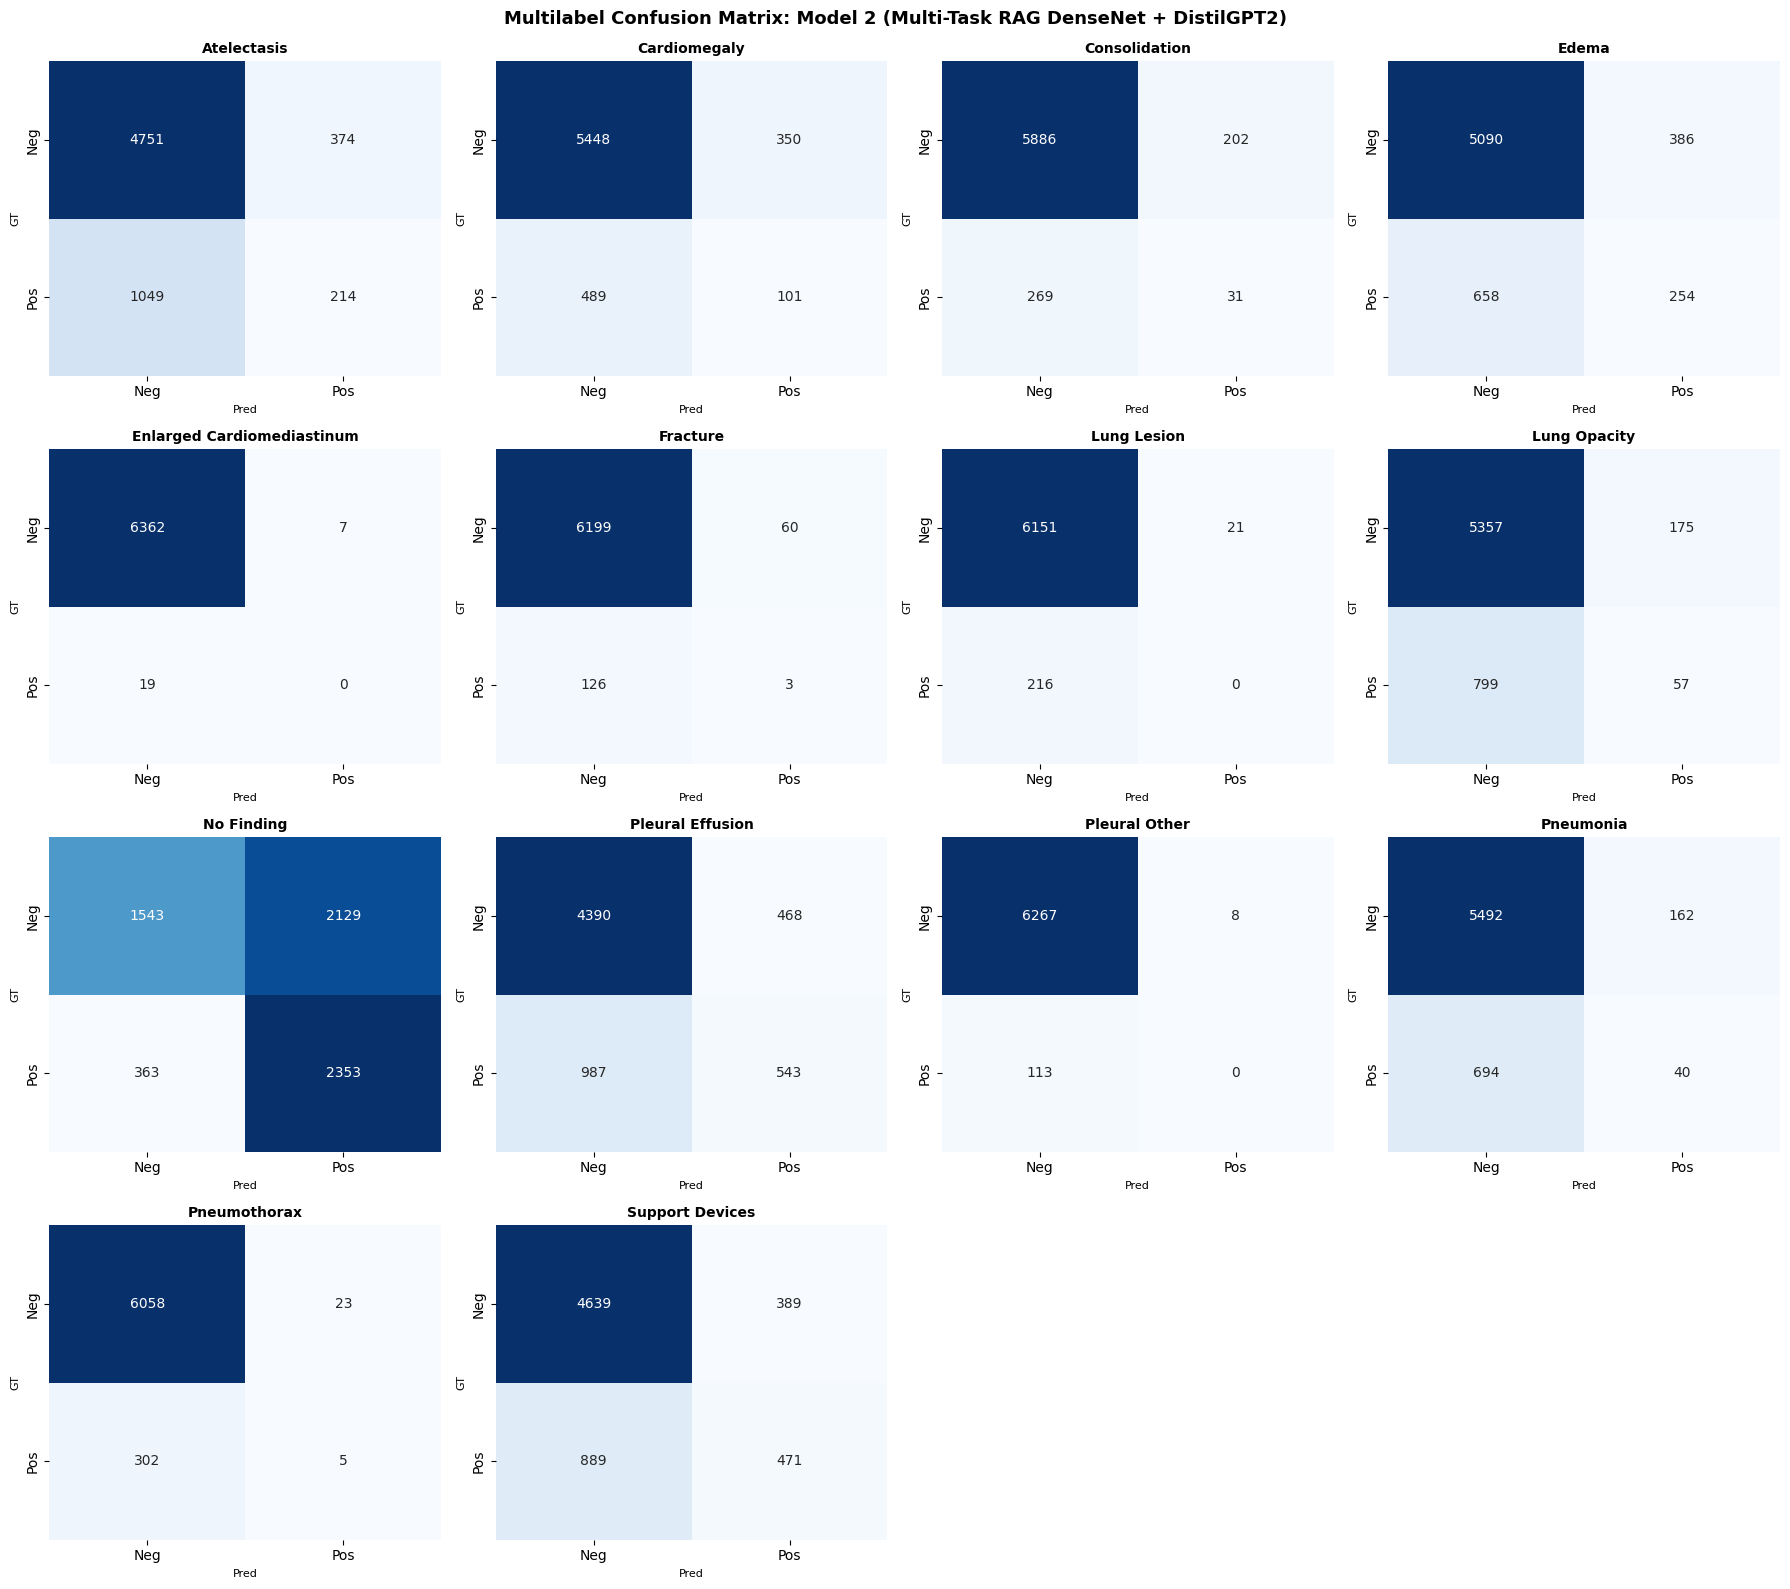

Model 2 Evaluation artifacts saved successfully to /kaggle/working/


In [4]:
# -------------------------------------------------------------------------
# 3. High-Speed Benchmark Evaluation Cell (5,731 Test Samples)
# -------------------------------------------------------------------------
!pip install rouge-score nltk seaborn matplotlib scikit-learn -q

import os, json, torch, pandas as pd, numpy as np, nltk, re
import matplotlib.pyplot as plt, seaborn as sns
from nltk.translate.bleu_score import sentence_bleu, SmoothingFunction
from nltk.util import ngrams
from rouge_score import rouge_scorer
from tqdm import tqdm
from sklearn.metrics import f1_score, precision_score, recall_score, multilabel_confusion_matrix, roc_auc_score

nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)

checkpoint_path = "/kaggle/working/model_2_best.pt"
if not os.path.exists(checkpoint_path):
    checkpoint_path = "/kaggle/working/model_2_resumable.pt"
    if os.path.exists(checkpoint_path):
        ckpt = torch.load(checkpoint_path, map_location=device)
        model.load_state_dict(ckpt['model_state'])
    else:
        raise FileNotFoundError("Model 2 checkpoint not found. Ensure Cell 3 execution.")
else:
    model.load_state_dict(torch.load(checkpoint_path, map_location=device))

model.eval()
print("Model 2 (Multi-Task RAG) Checkpoint loaded successfully.")

smooth = SmoothingFunction().method1
rouge_evaluator = rouge_scorer.RougeScorer(['rouge1', 'rouge2', 'rougeL'], use_stemmer=True)

clinical_keywords = {
    'Atelectasis': ['atelectasis', 'atelectatic', 'collapse', 'volume loss'],
    'Cardiomegaly': ['cardiomegaly', 'enlarged heart', 'enlarged cardiac', 'cardiac enlargement'],
    'Consolidation': ['consolidation', 'airspace disease', 'airspace opacity'],
    'Edema': ['edema', 'vascular congestion', 'fluid overload', 'interstitial edema'],
    'Enlarged Cardiomediastinum': ['widened mediastinum', 'mediastinal widening', 'cardiomediastinum'],
    'Fracture': ['fracture', 'fractured', 'broken rib', 'healing fracture'],
    'Lung Lesion': ['lung lesion', 'nodule', 'mass', 'nodular opacity'],
    'Lung Opacity': ['opacity', 'opacities', 'infiltrate', 'clouding'],
    'No Finding': ['normal', 'clear', 'unremarkable', 'no acute', 'negative'],
    'Pleural Effusion': ['pleural effusion', 'effusion', 'blunting', 'fluid in pleural'],
    'Pleural Other': ['pleural thickening', 'fibrosis', 'calcification'],
    'Pneumonia': ['pneumonia', 'infectious process', 'bronchopneumonia'],
    'Pneumothorax': ['pneumothorax', 'air in pleural', 'apical pneumothorax'],
    'Support Devices': ['tube', 'catheter', 'pacemaker', 'pacer', 'line', 'picc', 'stent']
}

negation_prefix_pattern = re.compile(r"\b(no|without|free of|negative for|absence of|denies|cleared of)\b\s*([\w\s]{0,35})$", re.IGNORECASE)
negation_suffix_pattern = re.compile(r"^([\w\s]{0,35})\s*\b(ruled out|is absent|resolved|excluded|unlikely|is not seen|not identified|has resolved|is clear)\b", re.IGNORECASE)

def detect_clinical_presence(text, keywords):
    text_lower = text.lower()
    for kw in keywords:
        matches = [m.start() for m in re.finditer(re.escape(kw), text_lower)]
        for match_idx in matches:
            prefix_window = text_lower[max(0, match_idx - 35):match_idx]
            suffix_window = text_lower[match_idx + len(kw):min(len(text_lower), match_idx + len(kw) + 35)]
            if not negation_prefix_pattern.search(prefix_window) and not negation_suffix_pattern.search(suffix_window):
                return 1
    return 0

print("Generating reports on " + str(len(test_dataset)) + " unseen test cases using RAG FAISS & KV Cache...")

results = []
bleu1_scores, bleu2_scores, bleu3_scores, bleu4_scores = [], [], [], []
rouge1_scores, rouge2_scores, rougeL_scores = [], [], []
distinct2_scores = []
gt_pathology_matrix = []
pred_pathology_matrix = []

with torch.no_grad():
    for idx in tqdm(range(len(test_dataset)), desc="Evaluating Model 2 Test Set"):
        row = test_df.iloc[idx]
        sample_batch = test_dataset[idx]
        spatial_token = sample_batch["spatial_tokens"].to(device)
        retrieved_r = sample_batch["retrieved_report"]
        
        gen_tokens = model.greedy_generate_rag(spatial_token, retrieved_r, max_len=60)
        pred_text = tokenizer.decode(gen_tokens, skip_special_tokens=True).strip()
        gt_text = str(row['report']).strip()
        
        ref_tokens = [nltk.word_tokenize(gt_text.lower())] if gt_text else [[""]]
        hyp_tokens = nltk.word_tokenize(pred_text.lower()) if pred_text else [""]
        
        b1 = sentence_bleu(ref_tokens, hyp_tokens, weights=(1, 0, 0, 0), smoothing_function=smooth)
        b2 = sentence_bleu(ref_tokens, hyp_tokens, weights=(0.5, 0.5, 0, 0), smoothing_function=smooth)
        b3 = sentence_bleu(ref_tokens, hyp_tokens, weights=(0.33, 0.33, 0.33, 0), smoothing_function=smooth)
        b4 = sentence_bleu(ref_tokens, hyp_tokens, weights=(0.25, 0.25, 0.25, 0.25), smoothing_function=smooth)
        
        rouge_res = rouge_evaluator.score(gt_text, pred_text)
        r1 = rouge_res['rouge1'].fmeasure
        r2 = rouge_res['rouge2'].fmeasure
        rL = rouge_res['rougeL'].fmeasure
        
        bleu1_scores.append(b1)
        bleu2_scores.append(b2)
        bleu3_scores.append(b3)
        bleu4_scores.append(b4)
        rouge1_scores.append(r1)
        rouge2_scores.append(r2)
        rougeL_scores.append(rL)
        
        if len(hyp_tokens) >= 2:
            bigrams = list(ngrams(hyp_tokens, 2))
            distinct2_scores.append(len(set(bigrams)) / len(bigrams))
        
        gt_row_labels = [detect_clinical_presence(gt_text, kws) for kws in clinical_keywords.values()]
        pred_row_labels = [detect_clinical_presence(pred_text, kws) for kws in clinical_keywords.values()]
        
        gt_pathology_matrix.append(gt_row_labels)
        pred_pathology_matrix.append(pred_row_labels)
        
        results.append({
            "dicom_id": row["dicom_id"],
            "study_id": row["study_id"],
            "ground_truth": gt_text,
            "prediction": pred_text,
            "retrieved_exemplar": retrieved_r,
            "bleu1": round(b1, 4),
            "bleu4": round(b4, 4),
            "rougeL": round(rL, 4)
        })

gt_matrix = np.array(gt_pathology_matrix)
pred_matrix = np.array(pred_pathology_matrix)

pathology_names = list(clinical_keywords.keys())
chexpert_gt_counts = np.array([test_df[col].sum() for col in pathology_names])
core_indices = [i for i, cnt in enumerate(chexpert_gt_counts) if cnt >= 100]

summary_metrics = {
    "Model": "Model 2 (Multi-Task RAG DenseNet + DistilGPT2)",
    "Test_Samples": len(results),
    "BLEU-1": round(float(np.mean(bleu1_scores)), 4),
    "BLEU-2": round(float(np.mean(bleu2_scores)), 4),
    "BLEU-3": round(float(np.mean(bleu3_scores)), 4),
    "BLEU-4": round(float(np.mean(bleu4_scores)), 4),
    "ROUGE-1": round(float(np.mean(rouge1_scores)), 4),
    "ROUGE-2": round(float(np.mean(rouge2_scores)), 4),
    "ROUGE-L": round(float(np.mean(rougeL_scores)), 4),
    "Distinct-2": round(float(np.mean(distinct2_scores)), 4) if distinct2_scores else 0.0,
    "Clinical_Macro_F1_All14": round(float(f1_score(gt_matrix, pred_matrix, average='macro', zero_division=0)), 4),
    "Clinical_Macro_F1_Core10": round(float(f1_score(gt_matrix[:, core_indices], pred_matrix[:, core_indices], average='macro', zero_division=0)), 4),
    "Clinical_Micro_F1": round(float(f1_score(gt_matrix, pred_matrix, average='micro', zero_division=0)), 4),
    "Clinical_Micro_Precision": round(float(precision_score(gt_matrix, pred_matrix, average='micro', zero_division=0)), 4),
    "Clinical_Micro_Recall": round(float(recall_score(gt_matrix, pred_matrix, average='micro', zero_division=0)), 4)
}

print("")
print("=" * 80)
print("OVERALL BENCHMARK: Model 2 (Multi-Task RAG DenseNet + DistilGPT2)")
print("=" * 80)
for k, v in summary_metrics.items():
    if k not in ["Model", "Test_Samples"]:
        print(f"{k:<30} | {v}")
print("=" * 80)

mcm = multilabel_confusion_matrix(gt_matrix, pred_matrix)
pathology_stats = []

print("")
print("=" * 110)
print("PER-PATHOLOGY CLINICAL BREAKDOWN: Model 2 (Proposal N >= 150 Threshold Flagging)")
print("=" * 110)
for i, name in enumerate(pathology_names):
    tn, fp, fn, tp = mcm[i].ravel()
    prec = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    rec  = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1   = 2 * prec * rec / (prec + rec) if (prec + rec) > 0 else 0.0
    official_chex_count = int(test_df[name].sum())
    warning_flag = "[!] Low Sample (N < 150)" if official_chex_count < 150 else "OK"
    pathology_stats.append({
        "Pathology": name, "TP": int(tp), "FP": int(fp), "FN": int(fn), "TN": int(tn),
        "Precision": round(prec, 4), "Recall": round(rec, 4), "F1_Score": round(f1, 4),
        "Official_CheXpert_Count": official_chex_count, "Sample_Status": warning_flag
    })
    print(f"{name:<26} | {tp:<5} | {fp:<5} | {fn:<5} | {tn:<5} | {prec:<7.4f} | {rec:<7.4f} | {f1:<7.4f} | {warning_flag}")

fig, axes = plt.subplots(4, 4, figsize=(18, 16))
axes = axes.flatten()
for i, name in enumerate(pathology_names):
    sns.heatmap(mcm[i], annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[i], xticklabels=["Neg", "Pos"], yticklabels=["Neg", "Pos"])
    axes[i].set_title(name, fontsize=10, fontweight='bold')
    axes[i].set_ylabel("GT", fontsize=8)
    axes[i].set_xlabel("Pred", fontsize=8)
for j in range(len(pathology_names), len(axes)):
    fig.delaxes(axes[j])

plt.suptitle("Multilabel Confusion Matrix: Model 2 (Multi-Task RAG DenseNet + DistilGPT2)", fontsize=13, fontweight='bold', y=0.99)
plt.tight_layout()
plt.savefig("/kaggle/working/model_2_confusion_matrices.png", dpi=300, bbox_inches='tight')
plt.show()

pd.DataFrame(results).to_csv("/kaggle/working/model_2_test_predictions.csv", index=False)
pd.DataFrame(pathology_stats).to_csv("/kaggle/working/model_2_pathology_breakdown.csv", index=False)
with open("/kaggle/working/model_2_test_metrics.json", "w") as f:
    json.dump(summary_metrics, f, indent=2)

print("Model 2 Evaluation artifacts saved successfully to /kaggle/working/")
